<a href="https://colab.research.google.com/github/jayaraksha/DEEP-LEARNING-SEM-5-/blob/main/Assignment%203DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q tensorflow scikit-learn pandas matplotlib seaborn


In [2]:
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [3]:
VOCAB_SIZE = 10000
MAX_LENGTH = 200

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("Positive reviews:", np.sum(y_train))
print("Negative reviews:", len(y_train) - np.sum(y_train))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
Positive reviews: 12500
Negative reviews: 12500


In [4]:
x_train = pad_sequences(
    x_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

x_test = pad_sequences(
    x_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)
print("Example review:", x_train[0])
print("Example label:", y_train[0])

Training data shape: (25000, 200)
Testing data shape: (25000, 200)
Example review: [   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480  284    5  150    4  172  112  167    2  336  385   39    4
  172 4536 1111   17  546   38   13  447    4  192   50   16    6  147
 2025   19   14   22    4 1920 4613  469    4   22   71   87   12   16
   43  530   38   76   15   13 1247    4   22   17  515   17   12   16
  626   18    2    5   62  386   12    8  316    8  106    5    4 2223
 5244   16  480   66 3785   33    4  130   12   16   38  619    5   25
  124   51   36  135   48   25 1415   33    6   22   12  215   28   77
   52    5   14  407   16   82    2    8    4  107  117 5952   15  256
    4    2    7 3766    5  723   36   71   43  530  476   26  400  317
   46    7    4    2 1029   13  104   88    4  381   15  297   98   32
 2071   56   26  141    6  194 7486   18    4  226   22   21  134

In [5]:
EMBEDDING_DIM = 64

def build_model(model_type):
    model = Sequential()

    model.add(
        Embedding(
            input_dim=VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True
        )
    )

    if model_type == "RNN":
        model.add(SimpleRNN(64))

    elif model_type == "LSTM":
        model.add(LSTM(64))

    elif model_type == "GRU":
        model.add(GRU(64))

    model.add(Dropout(0.3))
    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [6]:
models = {}
results = []
histories = {}

EPOCHS = 5
BATCH_SIZE = 64

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

for model_type in ["RNN", "LSTM", "GRU"]:

    print("\nTraining", model_type, "model...")

    model = build_model(model_type)

    start_time = time.time()

    history = model.fit(
        x_train,
        y_train,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_split=0.2,
        callbacks=[early_stop],
        verbose=1
    )

    training_time = time.time() - start_time

    y_prob = model.predict(x_test, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        "Model": model_type,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Training Time (seconds)": training_time
    })

    models[model_type] = model
    histories[model_type] = history

    print(classification_report(
        y_test, y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    ))

print("\nAll models trained successfully!")


Training RNN model...
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 34s 100ms/step - accuracy: 0.6154 - loss: 0.6449 - val_accuracy: 0.7736 - val_loss: 0.5049
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 99ms/step - accuracy: 0.7488 - loss: 0.5225 - val_accuracy: 0.6362 - val_loss: 0.6451
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 32s 101ms/step - accuracy: 0.8726 - loss: 0.3102 - val_accuracy: 0.6934 - val_loss: 0.6675
              precision    recall  f1-score   support

    Negative       0.72      0.86      0.78     12500
    Positive       0.82      0.67      0.74     12500

    accuracy                           0.76     25000
   macro avg       0.77      0.76      0.76     25000
weighted avg       0.77      0.76      0.76     25000


Training LSTM model...
Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 62s 189ms/step - accuracy: 0.7569 - loss: 0.4917 - val_accuracy: 0.8552 - val_loss: 0.3583
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 57s 181ms/step - accuracy: 0.8689 - loss: 0.3335 - val_accuracy: 0.8

In [7]:
results_df = pd.DataFrame(results)

print("Model Performance Comparison")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "Training Time (seconds)": "{:.2f}"
    })
)

results_df.to_csv(
    "sentiment_model_comparison.csv",
    index=False
)

Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (seconds)
0,RNN,0.7606,0.8216,0.6658,0.7356,106.10
1,LSTM,0.8394,0.8630,0.8070,0.8341,176.43
2,GRU,0.8406,0.8808,0.7878,0.8317,289.80


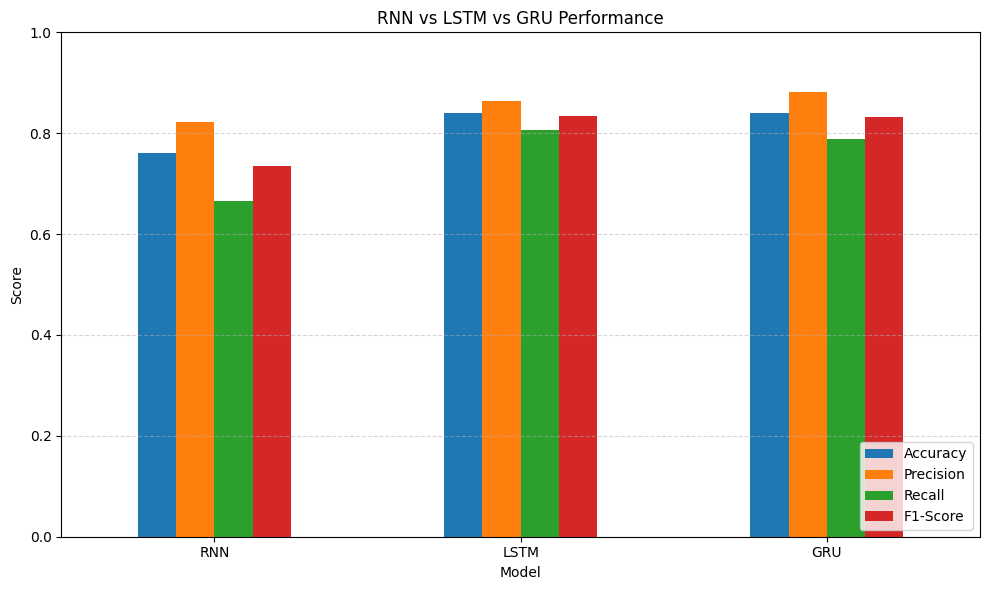

In [8]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("RNN vs LSTM vs GRU Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [9]:
best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

print("Best-performing model:", best_model_name)

print("\nBest model's results:")
display(
    results_df[
        results_df["Model"] == best_model_name
    ]
)

Best-performing model: LSTM

Best model's results:


,Model,Accuracy,Precision,Recall,F1-Score,Training Time (seconds)
1,LSTM,0.83944,0.86296,0.80704,0.834064,176.433315


In [10]:
word_index = imdb.get_word_index()

def preprocess_review(review):
    review = review.lower()
    review = re.sub(r"<br\s*/?>", " ", review)
    review = re.sub(r"[^a-zA-Z\s]", " ", review)

    words = review.split()
    sequence = [
        word_index.get(word, 2) + 3
        for word in words
        if word in word_index
    ]

    sequence = [
        idx if idx < VOCAB_SIZE else 2
        for idx in sequence
    ]

    padded = pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    return padded

review = input("Enter a movie review: ")

processed_review = preprocess_review(review)

prediction = models[best_model_name].predict(
    processed_review, verbose=0
)[0][0]

print("Sentiment:", "Positive" if prediction >= 0.5 else "Negative")
print("Positive probability:", round(float(prediction), 4))

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Enter a movie review: good
Sentiment: Positive
Positive probability: 0.5751


In [11]:
for name, model in models.items():
    model.save(f"{name.lower()}_sentiment_model.keras")

print("All three models saved successfully.")

All three models saved successfully.
